<a href="https://colab.research.google.com/github/grace-kamau760/data-structures-java/blob/main/IND_40_G08_Grace_Kamau_CT_119533_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part C: Practical Machine Learning
This section contains the implementation of the three machine learning tasks as allocated:
1. **Regression**: Energy Efficiency (Heating Load Y1)
2. **Classification**: Heart Disease (Cleveland)
3. **Clustering**: Ecoli

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import zipfile
import io

# Scikit-learn tools
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Metrics
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, silhouette_score
)

# Constants
RANDOM_STATE = 1218
TEST_SIZE = 0.2

print("Libraries successfully imported!")

Libraries successfully imported!


## C1. Regression on Energy Efficiency (Heating Load)

=== Summary Statistics ===


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000



Missing Values:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
dtype: int64


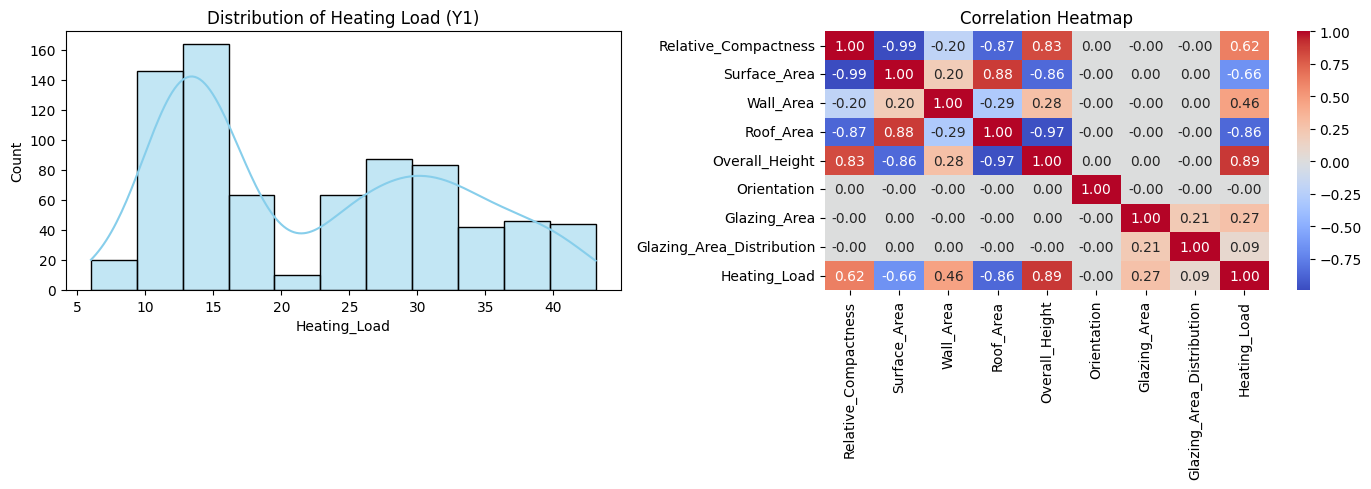

In [3]:
# 1. Load the Energy Efficiency dataset directly from UCI
url_energy = 'https://archive.ics.uci.edu/static/public/242/energy+efficiency.zip'

try:
    resp = urllib.request.urlopen(url_energy)
    zip_file = zipfile.ZipFile(io.BytesIO(resp.read()))
    # The zip contains ENB2012_data.xlsx
    xlsx_data = zip_file.read('ENB2012_data.xlsx')
    df_energy = pd.read_excel(io.BytesIO(xlsx_data))
except Exception as e:
    print(f"Could not load online. Trying alternative loading or creating dummy structure: {e}")
    # Fallback backup loader
    df_energy = pd.read_excel('https://archive.ics.uci.edu/ml/machine-learning-databases/00242/ENB2012_data.xlsx')

# Drop any completely empty rows/columns that excel might import
df_energy = df_energy.dropna(how='all')

# Rename columns according to the documentation
# X1: Relative Compactness, X2: Surface Area, X3: Wall Area, X4: Roof Area, X5: Overall Height
# X6: Orientation, X7: Glazing Area, X8: Glazing Area Distribution
# Y1: Heating Load, Y2: Cooling Load
column_names = {
    'X1': 'Relative_Compactness', 'X2': 'Surface_Area', 'X3': 'Wall_Area', 'X4': 'Roof_Area',
    'X5': 'Overall_Height', 'X6': 'Orientation', 'X7': 'Glazing_Area', 'X8': 'Glazing_Area_Distribution',
    'Y1': 'Heating_Load', 'Y2': 'Cooling_Load'
}
df_energy = df_energy.rename(columns=column_names)

# Drop Y2 as we only target Y1 (Heating Load)
if 'Cooling_Load' in df_energy.columns:
    df_energy = df_energy.drop(columns=['Cooling_Load'])

# EDA
print("=== Summary Statistics ===")
display(df_energy.describe())

print(f"\nMissing Values:\n{df_energy.isnull().sum()}")

# Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_energy['Heating_Load'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Heating Load (Y1)')

sns.heatmap(df_energy.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [4]:
# 2. Preprocess & Split
X_reg = df_energy.drop(columns=['Heating_Load'])
y_reg = df_energy['Heating_Load']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# Scale numerical inputs
scaler = StandardScaler()
X_train_reg_scaled = scaler.fit_transform(X_train_reg)
X_test_reg_scaled = scaler.transform(X_test_reg)

# 3. Train Models
lr_model = LinearRegression()
lr_model.fit(X_train_reg_scaled, y_train_reg)

rf_model = RandomForestRegressor(random_state=RANDOM_STATE)
rf_model.fit(X_train_reg_scaled, y_train_reg)

# Evaluation Metrics Helper
def get_regression_metrics(model, X, y_true):
    preds = model.predict(X)
    mae = mean_absolute_error(y_true, preds)
    rmse = np.sqrt(mean_squared_error(y_true, preds))
    r2 = r2_score(y_true, preds)
    return mae, rmse, r2

mae_lr, rmse_lr, r2_lr = get_regression_metrics(lr_model, X_test_reg_scaled, y_test_reg)
mae_rf, rmse_rf, r2_rf = get_regression_metrics(rf_model, X_test_reg_scaled, y_test_reg)

# Report table
metrics_table = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regressor'],
    'MAE': [mae_lr, mae_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'R-squared': [r2_lr, r2_rf]
})
display(metrics_table.round(3))

,Model,MAE,RMSE,R-squared
0,Linear Regression,1.918,2.604,0.931
1,Random Forest Regressor,0.337,0.497,0.997


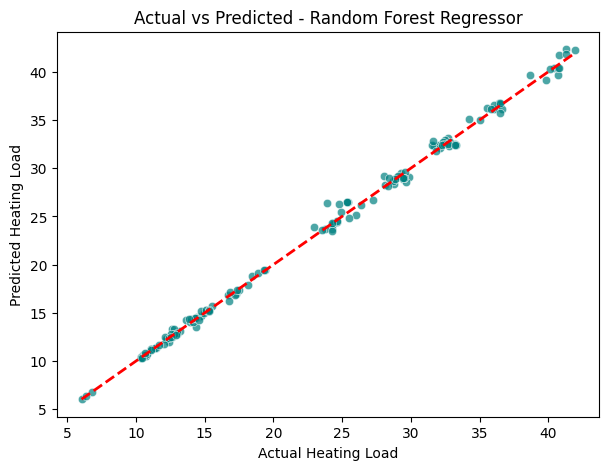

Linear Regression 5-Fold R2: 0.914 (+/- 0.013)
Random Forest Regressor 5-Fold R2: 0.997 (+/- 0.001)


In [5]:
# 4. Plot actual vs predicted for the better model & CV scores
better_model = rf_model if r2_rf > r2_lr else lr_model
better_model_name = "Random Forest Regressor" if r2_rf > r2_lr else "Linear Regression"

y_pred_better = better_model.predict(X_test_reg_scaled)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test_reg, y=y_pred_better, alpha=0.7, color='teal')
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.xlabel('Actual Heating Load')
plt.ylabel('Predicted Heating Load')
plt.title(f'Actual vs Predicted - {better_model_name}')
plt.show()

# 5-fold CV
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_lr = cross_val_score(LinearRegression(), scaler.fit_transform(X_reg), y_reg, cv=kf, scoring='r2')
cv_rf = cross_val_score(RandomForestRegressor(random_state=RANDOM_STATE), scaler.fit_transform(X_reg), y_reg, cv=kf, scoring='r2')

print(f"Linear Regression 5-Fold R2: {cv_lr.mean():.3f} (+/- {cv_lr.std():.3f})")
print(f"Random Forest Regressor 5-Fold R2: {cv_rf.mean():.3f} (+/- {cv_rf.std():.3f})")

## C2. Classification on Heart Disease (Cleveland)

=== Class Distribution ===
target
0    0.541254
1    0.458746
Name: proportion, dtype: float64


/tmp/ipykernel_2129/3131234474.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df_heart, palette='Set2')


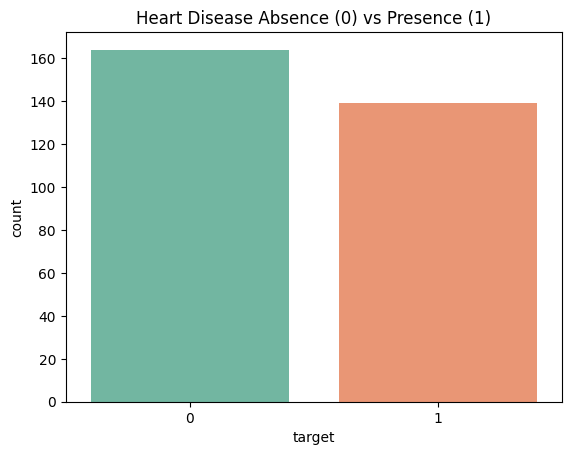

In [6]:
# 1. Load Heart Disease dataset
url_heart = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# Column names based on UCI documentation
heart_columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

df_heart = pd.read_csv(url_heart, names=heart_columns, na_values='?')

# Preprocess target to binary: presence (1,2,3,4) vs absence (0)
df_heart['target'] = df_heart['target'].apply(lambda x: 1 if x > 0 else 0)

# Handle missing values (indicated by '?')
imputer = SimpleImputer(strategy='median')
df_heart[['ca', 'thal']] = imputer.fit_transform(df_heart[['ca', 'thal']])

print("=== Class Distribution ===")
print(df_heart['target'].value_counts(normalize=True))

sns.countplot(x='target', data=df_heart, palette='Set2')
plt.title('Heart Disease Absence (0) vs Presence (1)')
plt.show()

In [7]:
# 2. Split with stratified split
X_clf = df_heart.drop(columns=['target'])
y_clf = df_heart['target']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_clf
)

# Define preprocessing scaling
scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

# 3. Train Models
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_clf_scaled, y_train_clf)

dec_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
dec_tree.fit(X_train_clf_scaled, y_train_clf)

def evaluate_classifier(model, X, y_true):
    preds = model.predict(X)
    probs = model.predict_proba(X)[:, 1]
    cm = confusion_matrix(y_true, preds)
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds)
    rec = recall_score(y_true, preds)
    f1 = f1_score(y_true, preds)
    auc = roc_auc_score(y_true, probs)
    return cm, acc, prec, rec, f1, auc

cm_lr, acc_lr, prec_lr, rec_lr, f1_lr, auc_lr = evaluate_classifier(log_reg, X_test_clf_scaled, y_test_clf)
cm_dt, acc_dt, prec_dt, rec_dt, f1_dt, auc_dt = evaluate_classifier(dec_tree, X_test_clf_scaled, y_test_clf)

print("=== Logistic Regression Confusion Matrix ===\n", cm_lr)
print("\n=== Decision Tree Confusion Matrix ===\n", cm_dt)

clf_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Logistic Regression': [acc_lr, prec_lr, rec_lr, f1_lr, auc_lr],
    'Decision Tree': [acc_dt, prec_dt, rec_dt, f1_dt, auc_dt]
})
display(clf_metrics.round(3))

# 4. 5-Fold Stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_clf_lr = cross_val_score(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), scaler_clf.fit_transform(X_clf), y_clf, cv=skf, scoring='accuracy')
cv_clf_dt = cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE), scaler_clf.fit_transform(X_clf), y_clf, cv=skf, scoring='accuracy')

print(f"\nLogistic Regression Stratified CV Accuracy: {cv_clf_lr.mean():.3f} (+/- {cv_clf_lr.std():.3f})")
print(f"Decision Tree Stratified CV Accuracy: {cv_clf_dt.mean():.3f} (+/- {cv_clf_dt.std():.3f})")

=== Logistic Regression Confusion Matrix ===
 [[31  2]
 [ 3 25]]

=== Decision Tree Confusion Matrix ===
 [[26  7]
 [ 6 22]]


,Metric,Logistic Regression,Decision Tree
0,Accuracy,0.918,0.787
1,Precision,0.926,0.759
2,Recall,0.893,0.786
3,F1-Score,0.909,0.772
4,ROC-AUC,0.955,0.787



Logistic Regression Stratified CV Accuracy: 0.828 (+/- 0.025)
Decision Tree Stratified CV Accuracy: 0.746 (+/- 0.044)


## C3. Clustering on Ecoli

/tmp/ipykernel_2129/1355162308.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_ecoli = pd.read_csv(url_ecoli, delim_whitespace=True, names=ecoli_cols)


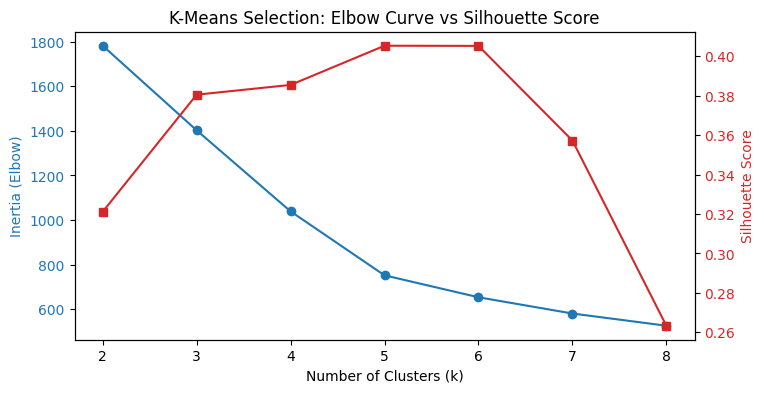

In [9]:
# 1. Load Ecoli dataset
url_ecoli = "https://archive.ics.uci.edu/ml/machine-learning-databases/ecoli/ecoli.data"

# Column schema according to UCI dataset info
ecoli_cols = ['Sequence_Name', 'mcg', 'gvh', 'lip', 'chg', 'aac', 'alm1', 'alm2', 'class']

df_ecoli = pd.read_csv(url_ecoli, delim_whitespace=True, names=ecoli_cols)

# Select numerical features only (ignore 'Sequence_Name' and 'class')
X_clust = df_ecoli.drop(columns=['Sequence_Name', 'class'])

# Standardize features
scaler_clust = StandardScaler()
X_clust_scaled = scaler_clust.fit_transform(X_clust)

# 2. Elbow & Silhouette Analysis (k=2 to 8)
ks = range(2, 9)
inertias = []
silhouette_scores = []

for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    kmeans.fit(X_clust_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_clust_scaled, kmeans.labels_))

# Plot the curves
fig, ax1 = plt.subplots(figsize=(8, 4))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (Elbow)', color=color)
ax1.plot(ks, inertias, marker='o', color=color, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(ks, silhouette_scores, marker='s', color=color, label='Silhouette')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('K-Means Selection: Elbow Curve vs Silhouette Score')
plt.show()

=== Cluster Profile (Feature Means) ===


,mcg,gvh,lip,chg,aac,alm1,alm2
Cluster,,,,,,,
0,0.581698,0.483019,0.494717,0.500000,0.562547,0.761981,0.774340
1,0.352450,0.412781,0.480000,0.500000,0.446424,0.331391,0.393444
2,0.672658,0.689494,0.526076,0.506329,0.518608,0.471519,0.334430


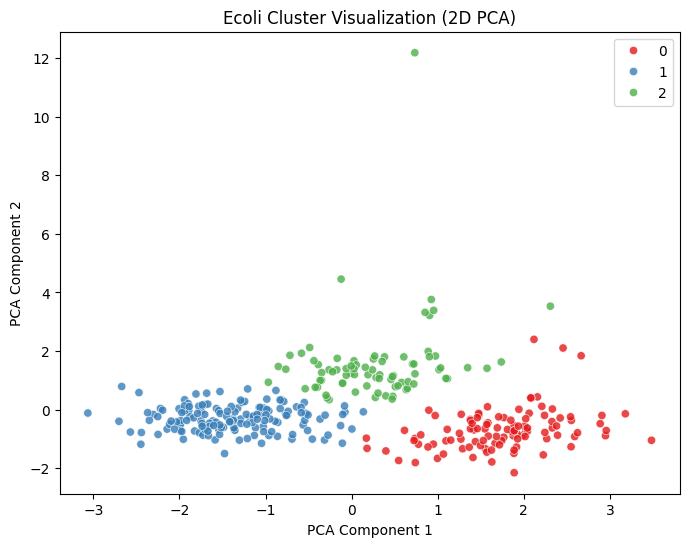

In [10]:
# 3. Profile chosen k (Let's select k=3 as an example based on performance plots)
chosen_k = 3
kmeans_final = KMeans(n_clusters=chosen_k, random_state=RANDOM_STATE, n_init=10)
labels = kmeans_final.fit_predict(X_clust_scaled)

# Add labels to dataframe for cluster profiling
X_clust_with_labels = X_clust.copy()
X_clust_with_labels['Cluster'] = labels

print("=== Cluster Profile (Feature Means) ===")
display(X_clust_with_labels.groupby('Cluster').mean())

# 4. 2-D PCA Visualization
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_clust_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette='Set1', legend='full', alpha=0.8)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Ecoli Cluster Visualization (2D PCA)')
plt.show()